# Exploring Wavelet Tranforms for Image Compression

Image compression is a fundamental problem in computer science. Namely, if we think about an image as a matrix with integer values (telling us what color to use at various pixel locations), this data can get extremely costly - a 256x256 pixel image, which *only* uses black and white would need at least $256^2 \text{(Pixel locations)} * 2 \text{ bytes (Shading information)} \sim 131 \text{kb}$ worth of storage. Mind you, this would be considered a *small* image! 

Of course, it would be ideal if we were able to somehow express the same amount of information while also needing less storage - especially for dealing with more costly formats (e.g. for videos or extremely high resolution images). Wavelets & more specifically discrete wavelet transforms offer a surprising solution to handle this issue, and the ideas behind these transforms are common practice in many modern compression formats. 


## 0. Set-up

In [1]:
from vision.utils import load_image, save_image

If that didn't throw an error, then you're good to proceed! Then we make sure our pictures are properly loading.

(207, 220, 3)
[[[0.         0.83137256 0.        ]
  [0.         0.8392157  0.        ]
  [0.         0.8392157  0.        ]
  [0.         0.84313726 0.        ]
  [0.         0.8627451  0.        ]]

 [[0.         0.827451   0.        ]
  [0.         0.84313726 0.        ]
  [0.         0.84313726 0.        ]
  [0.         0.84705883 0.        ]
  [0.         0.85490197 0.        ]]

 [[0.         0.8509804  0.        ]
  [0.         0.85882354 0.        ]
  [0.         0.8509804  0.        ]
  [0.         0.8392157  0.        ]
  [0.         0.84313726 0.        ]]

 [[0.         0.84313726 0.        ]
  [0.         0.85882354 0.        ]
  [0.         0.8627451  0.        ]
  [0.         0.8627451  0.        ]
  [0.         0.8627451  0.        ]]

 [[0.         0.8509804  0.        ]
  [0.         0.8666667  0.        ]
  [0.         0.8666667  0.        ]
  [0.         0.85490197 0.        ]
  [0.         0.84705883 0.        ]]]


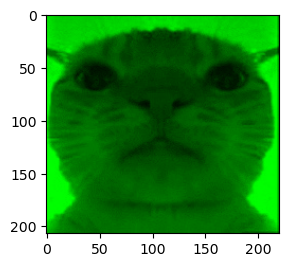

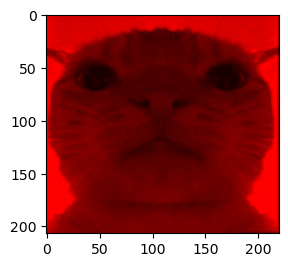

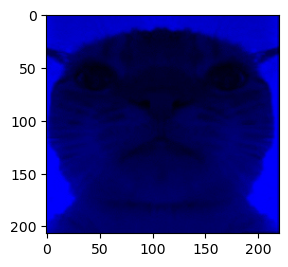

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import skimage as ski
from vision.utils import load_image, save_image

catim = load_image('data/madcat.jpg')
print(catim.shape)
colordict = {'red': 1, 'blue': 0, 'green': 2}
def get_cat(color, img):
    newcat = img.copy()
    for i in range(0, 3):
        if i != colordict[color]:
            newcat[:, :, i] = 0
            
    return newcat

plt.figure(figsize=(3,3)); plt.imshow((get_cat('red', catim)*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((get_cat('blue', catim)*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((get_cat('green', catim)*255).astype(np.uint8));

print(get_cat('red', catim)[:5, :5, :])



## 1. Naive approach to compression

For the sake of gaining an appreciation for the more sophisticated approaches we shall see later, it might be helpful to first imagine the most intuitive thing one might try to *reduce* the amount of data needed for a particular photo. A particularly easy thing we might try to take a small average around each group of pixels, and replace all the pixels with the value of the average - i.e. an operation like the following:

$$ \begin{pmatrix} a & b & c \\ d & e & f \\ g & h & i \end{pmatrix} \Rightarrow \begin{pmatrix} x & x & x \\ x & x & x \\ x & x & x \end{pmatrix} $$

where $x$ denotes the average value, that is, $x = \frac{1}{9}(a + b + \cdots + i) $. Thus, if we repeat this process throughout our pixel matrix, we will have reduced the amount of data needed by 1/9th!

In [15]:
print(catim[0:5, 0, 0])
np.zeros((5, 2, 3))

[0.85882354 0.85490197 0.8784314  0.87058824 0.8784314 ]


array([[[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]]])

In [134]:
def n_box_average(n, img):
        height = img.shape[0]
        width = img.shape[1]
        new_img = np.zeros((height // n + 1, width // n + 1, 3))
        for i in range(0, height, n):
            for j in range(0, width, n):
                for col in [0, 1, 2]:
                    color_tot = 0
                    summed = 0
                    for x in range(n):
                        for y in range(n):
                            if i + x < height and j + y < width:
                                #print('ok, we made it this far')
                                color_tot += img[i + x, j + y, col]
                                summed += 1
                    if summed != 0:
                        color_avg = color_tot / (summed)
                    else:
                        color_avg = 0
                    new_idx, new_idy = i // n, j // n
                    #print('was it the array assign?')
                    #print(new_idx, new_idy)
                    new_img[new_idx, new_idy, col] = color_avg
        return new_img
    #except:
    #    print('Image does not have required format.')
    #    return new_img

In [135]:
print(catim.shape)
print(catim.shape[0] // 5)
avg_catim = n_box_average(4, catim)

(207, 220, 3)
41


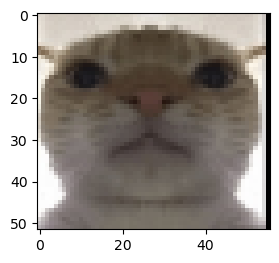

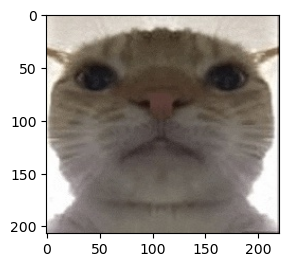

In [136]:
plt.figure(figsize=(3,3)); plt.imshow((avg_catim*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((catim*255).astype(np.uint8));


### Some small problems

In the first of the two above images, we see our compressed image. In the second, our original image. Certainly, we have saved ourselves a bit of information, but we right away see two major issues:

1. There are obvious visual artifacts from our compression - in other words, we clearly have a worse image than what we started with
2. There is no way that we could reverse the process above to get our original image back - if we didn't keep a separate copy, then this image would be lost for good!

## 2. Slightly less naive: "Smart" detail reduction

Look at the two zoomed in pictures below, and take a second to notice any major differences:

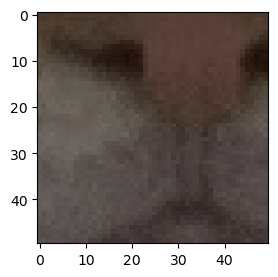

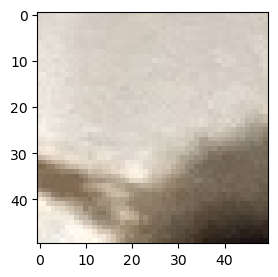

In [68]:
nose_catim = catim[75:125, 75:125, :]
background = catim[0:50, 0:50, :]
plt.figure(figsize=(3,3)); plt.imshow((nose_catim*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((background*255).astype(np.uint8));

The first clearly has more detailed features - nostrils, whiskers, mouth, nose (which is a more reddish color than the rest), while the second (at least the top half) is mostly just background of the exact same color. Therefore, if we were to apply average to *only* the background parts, we might hope that we could get some gains from compression for essentially *no loss* in image quality!

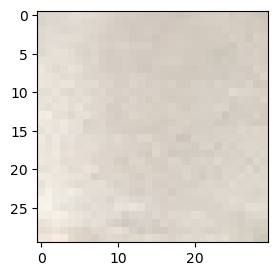

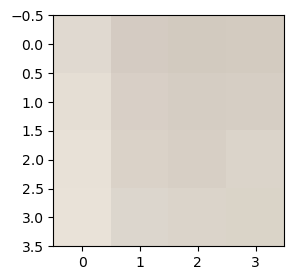

In [79]:
background_small = background[0:30, 0:30, :]
back_reduced = n_box_average(8, background_small)
plt.figure(figsize=(3,3)); plt.imshow((background_small*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((back_reduced*255).astype(np.uint8));


Above, we see just the background portion of the previous image, and below it, the same picture but after applying a convolution filter. One can tell a bit up close, but perhaps at a distance, the two will look identical.

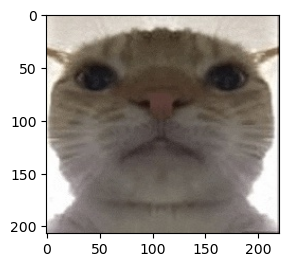

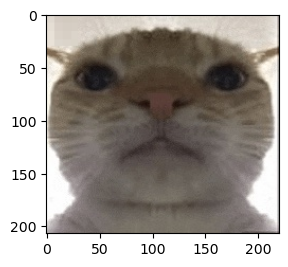

In [81]:
background_small = catim[0:30, 0:30, :]
back_reduced = n_box_average(8, background_small)
adjusted_img = catim.copy()
for i in range(0, 30, 8):
            for j in range(0, 30, 8):
                for col in [0, 1, 2]:
                    color_tot = 0
                    summed = 0
                    for x in range(8):
                        for y in range(8):
                            if i + x < 30 and j + y < 30:
                                #print('ok, we made it this far')
                                x_ind, y_ind = i // 8, j // 8
                                adjusted_img[i + x, j + y, col] = back_reduced[x_ind, y_ind, col]
plt.figure(figsize=(3,3)); plt.imshow((catim*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((adjusted_img*255).astype(np.uint8));

Indeed, noting that the second image is the image with our "smart" convolution applied to it, we see that this image is hardly distinguishable from the first. However, we again have some issues:
1. We had to pick our "smart" pixel range by hand - and although we could do this algorithmically (say by looking at sup_{pixel in nxn matrix} |avg_pixel - pixel|, and setting a pre-set threshold, it would not necessarily be as accurate as the manual way
2. It may be that much of the image is not background! Hence the compression gain will be relatively small

## 3. Wavelet Transforms
Here we investigate what will happen to an image if we try using a standard Haar Decomposition with various levels of approximation

In [3]:
import pywt #This is the python wavelet library we will be using for the rest of the notebook

In [83]:
# Note that there are a lot of wavelet families to choose from
pywt.families()

['haar',
 'db',
 'sym',
 'coif',
 'bior',
 'rbio',
 'dmey',
 'gaus',
 'mexh',
 'morl',
 'cgau',
 'shan',
 'fbsp',
 'cmor']

The first example we want to try is with the most simple Haar functions - so we create a Wavelet object using this family

In [84]:
w = pywt.Wavelet('haar')
print(w)

Wavelet haar
  Family name:    Haar
  Short name:     haar
  Filters length: 2
  Orthogonal:     True
  Biorthogonal:   True
  Symmetry:       asymmetric
  DWT:            True
  CWT:            False


The most fundamental method we use is pywt.dwt (short for Discrete Wavelet Transform). If one is familiar with fast fourier transforms, this is very doing a similar computation, except based on the real-valued functions given by the haar wavelets (rather then the exponential functions, which are the basis of the fourier transforms)

In [4]:
samp_arr = [1, -1, 1, -1, 1, -1, 1, -1]
cA, cD = pywt.dwt(samp_arr, 'haar')
print(cA)
print(cD)

[0. 0. 0. 0.]
[1.41421356 1.41421356 1.41421356 1.41421356]


**Note:** we obtain two output arrays: ``cA`` and ``cD``. In technical terms, ``cA`` consists of the ***approximation coefficients*** and ``cD`` consists of the ***detail coefficients***. I won't go into detail here about the differences between the two, but just note that for our purposes, we really only care about the approximation coefficients. If you want to understand more what exactly this computation is doing, I **highly** recommend either checking out the slides I included in the github project, or checking out this video: https://www.youtube.com/watch?v=c1XL5BeI9_s (Note: the video is **not** my work - but I think the visualizations are really great!)

The python wavelet package also includes a pywt.idwt method (short for inverse discrete wavelet transform). We will not explore this too much here, but the point is that given the **approximation coefficients** ``cA`` as well as the **detail coefficients** ``cD``, we can combine these to get back our starting array, ``samp_arr``. 

In [5]:
pywt.idwt(cA, cD, 'haar')

array([ 1., -1.,  1., -1.,  1., -1.,  1., -1.])

Since we are in a new section, we load a new fun cat image to work with:

(512, 512, 3)


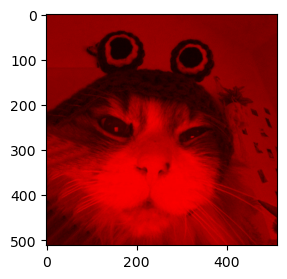

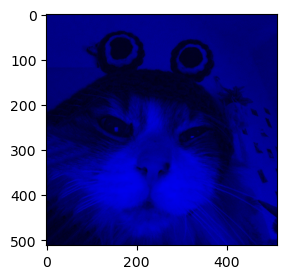

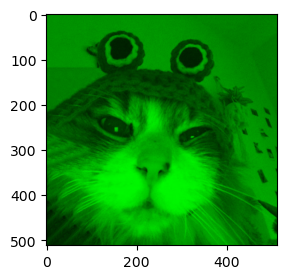

In [139]:
catim = load_image('data/goofycat.jpg')
print(catim.shape)
colordict = {'green': 1, 'red': 0, 'blue': 2}
plt.figure(figsize=(3,3)); plt.imshow((get_cat('red', catim)*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((get_cat('blue', catim)*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((get_cat('green', catim)*255).astype(np.uint8));


We then save the color-channel restricted matrices into new variables (which we will be thinking about as $256^2$ length *arrays* that we will apply wavelet transforms to):

In [140]:
redcat = get_cat('red', catim)[:, :, colordict['red']]
bluecat = get_cat('blue', catim)[:, :, colordict['blue']]
greencat = get_cat('green', catim)[:, :, colordict['green']]
redcat.shape

(512, 512)

In [195]:
redcatdata = pywt.wavedec2(redcat, 'haar', level = 5)
bluecatdata = pywt.wavedec2(bluecat, 'haar', level = 5)
greencatdata = pywt.wavedec2(greencat, 'haar', level = 5)


#bluecat = pywt.dwt2(bluecat, 'haar')
#greencatA, greencatD = pywt.dwt2(greencat, 'haar')
#print(redcatdata)
#Note this has form [cAn, (cHn, cVn, cDn), … (cH1, cV1, cD1)], with n = level
#Say we want to reduce this down to size of only N coefficients
print(redcatdata[1][0].shape)
def find_max_N(data, N):
    #Definitely need approximation array, so dont even look through that
    new_arr = []
    for tup in data[1:]:
        for arr in tup:
            arr2 = arr.flatten()
            for i in range(len(arr2)):
                new_arr.append(abs(arr2[i]))
    arr3 = np.sort(new_arr)
    maxval = arr3[len(arr3) - N]
    
    data2 = data.copy()
    for i in range(len(data[1:])): #data[1:][i] is a tuple (a,b,c)
        for j in range(len(data[1:][i])):
            for k in range(len(data[1:][i][j])): #data[1:][i][j] is a 16x16 array
                for h in range(len(data[1:][i][j][k])):
                    if abs(data[1:][i][j][k][h]) < maxval:
                        data2[1:][i][j][k][h] = 0
    return data2
    #print(new_arr[len(arr3) - N])
    
redcat_red = find_max_N(redcatdata, 4096)
bluecat_red = find_max_N(bluecatdata, 4096)
greencat_red = find_max_N(greencatdata,4096)

(16, 16)


### 3.1 Inverses / Compression

Let's see what happens if we compute the inverse wavelet transform but **drop** the second array - in other words, we should not quite be able to reproduce our original picture (since we have excluded half of the original coefficients our wavelet transform produced)... but perhaps we can get close..?

In [196]:
redcatFiltered = pywt.waverec2(redcat_red, 'haar')
bluecatFiltered = pywt.waverec2(bluecat_red, 'haar')
greencatFiltered = pywt.waverec2(greencat_red, 'haar')
redcatFiltered.shape

(512, 512)

In [197]:
#first -need to remake into 512x512x3 matrices
redcatFilteredReal = np.stack([redcatFiltered, np.zeros((512, 512)), np.zeros((512, 512))], axis=2)
redcatFilteredReal.shape
bluecatFilteredReal = np.stack([np.zeros((512, 512)), np.zeros((512, 512)), bluecatFiltered], axis=2)
greencatFilteredReal = np.stack([np.zeros((512, 512)), greencatFiltered, np.zeros((512, 512))], axis=2)

In [198]:
totalcatFiltered = np.add(np.add(redcatFilteredReal, bluecatFilteredReal), greencatFilteredReal)

In [130]:
print(get_cat('red', catim)[:5, :5, :])

[[[0.5254902  0.         0.49411765]
  [0.5372549  0.         0.5058824 ]
  [0.5372549  0.         0.5058824 ]
  [0.53333336 0.         0.5019608 ]
  [0.54509807 0.         0.5137255 ]]

 [[0.5568628  0.         0.5254902 ]
  [0.56078434 0.         0.5294118 ]
  [0.5529412  0.         0.52156866]
  [0.54509807 0.         0.5137255 ]
  [0.5529412  0.         0.52156866]]

 [[0.5647059  0.         0.53333336]
  [0.5647059  0.         0.53333336]
  [0.5529412  0.         0.52156866]
  [0.5411765  0.         0.50980395]
  [0.54509807 0.         0.5137255 ]]

 [[0.5529412  0.         0.52156866]
  [0.5529412  0.         0.52156866]
  [0.54901963 0.         0.5176471 ]
  [0.5411765  0.         0.50980395]
  [0.54509807 0.         0.5137255 ]]

 [[0.54509807 0.         0.5137255 ]
  [0.54509807 0.         0.5137255 ]
  [0.5529412  0.         0.52156866]
  [0.56078434 0.         0.5294118 ]
  [0.56078434 0.         0.5294118 ]]]


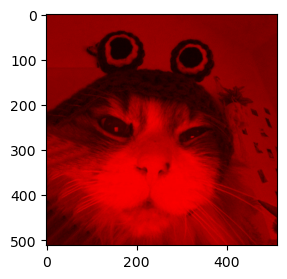

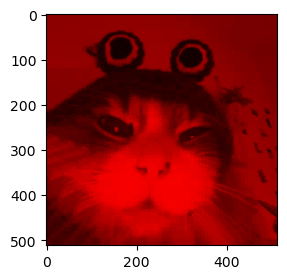

In [199]:
plt.figure(figsize=(3,3)); plt.imshow((get_cat('red', catim)*255).astype(np.uint8));
plt.figure(figsize=(3,3)); plt.imshow((redcatFilteredReal*255).astype(np.uint8));
#print(redcatFiltered.shape)
#print(redcatFiltered[:5, :5, :])
#catFiltered = np.stack([redcatFiltered, bluecatFiltered, greencatFiltered], axis=2)
#catFiltered.shape
#plt.figure(figsize=(3,3)); plt.imshow((catFiltered*255).astype(np.uint8));


Pictured first is the (red channel) of our original image, and then our same image after losing 1/4th of the data from applying our discrete wavelet transform --> dropping the detail coefficients --> applying the inverse discrete wavelet transform.

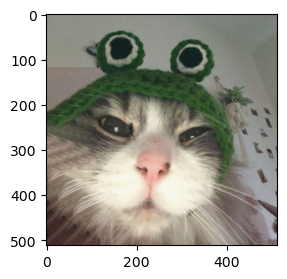

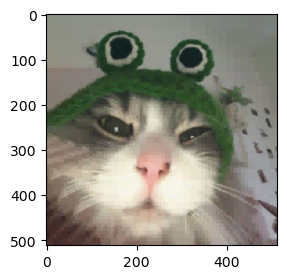

In [200]:
plt.figure(figsize=(3,3)); plt.imshow((catim*255).astype(np.uint8));

plt.figure(figsize=(3,3)); plt.imshow((totalcatFiltered*255).astype(np.uint8));


### 3.2 The result

It turns out - what we get is really good! And we only used **one fourth** of the coefficients! (since we used one 256x256 matrix, rather than a 512 by 512 matrix). Moreover, by applying more and more rounds of discrete wavelet transforms, we could have gotten a more and more refined compression (at the increasing cost of visual quality of our image). Overall - much better than our naive approach!